In [3]:
import pandas as pd
import numpy as np

try:
    campaigns = pd.read_csv('campaigns.csv')
    events = pd.read_csv('events.csv')
    transactions = pd.read_csv('transactions.csv')
    print("Успех! Все файлы успешно загружены.")
except FileNotFoundError as e:
    print(f"Ошибка: Не удалось найти файл. Проверьте путь. Детали: {e}")
    
# 2. Первичное знакомство с объемами данных
print("\n--- Размерности таблиц ---")
print(f"Кампании: {campaigns.shape[0]} строк, {campaigns.shape[1]} столбцов")
print(f"События (Логи): {events.shape[0]} строк, {events.shape[1]} столбцов")
print(f"Транзакции (Продажи): {transactions.shape[0]} строк, {transactions.shape[1]} столбцов")

# 3. Смотрим на типы данных и пропуски в таблице событий (она ключевая)
print("\n--- Информация о таблице Events ---")
print(events.info())

Успех! Все файлы успешно загружены.

--- Размерности таблиц ---
Кампании: 50 строк, 7 столбцов
События (Логи): 2000000 строк, 12 столбцов
Транзакции (Продажи): 103127 строк, 9 столбцов

--- Информация о таблице Events ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 12 columns):
 #   Column                Dtype  
---  ------                -----  
 0   event_id              int64  
 1   timestamp             object 
 2   customer_id           int64  
 3   session_id            int64  
 4   event_type            object 
 5   product_id            float64
 6   device_type           object 
 7   traffic_source        object 
 8   campaign_id           int64  
 9   page_category         object 
 10  session_duration_sec  float64
 11  experiment_group      object 
dtypes: float64(2), int64(4), object(6)
memory usage: 183.1+ MB
None


In [2]:
#В транзакциях есть возвраты (refund_flag = 1) и отрицательная выручка. 
#Нам нужно посчитать чистую выручку (Net Revenue), чтобы не завышать показатели прибыльности групп.

Python сейчас работает в этой папке:
C:\Users\Пользователь


In [4]:
# 1. Переводим столбцы с датами из текста в формат Datetime
events['timestamp'] = pd.to_datetime(events['timestamp'])
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])

# 2. Создаем столбец чистой выручки (Net Revenue)
# Бизнес-логика: если был возврат (refund_flag == 1), то чистая выручка равна 0, иначе она равна gross_revenue
transactions['net_revenue'] = np.where(transactions['refund_flag'] == 1, 0, transactions['gross_revenue'])

print("--- Проверка расчета чистой выручки ---")
print(transactions[['gross_revenue', 'refund_flag', 'net_revenue']].head(15))

--- Проверка расчета чистой выручки ---
    gross_revenue  refund_flag  net_revenue
0           43.74            0        43.74
1          174.78            0       174.78
2           40.61            0        40.61
3           68.76            0        68.76
4           14.64            0        14.64
5          169.74            0       169.74
6           42.48            0        42.48
7           36.95            0        36.95
8          125.59            0       125.59
9           48.72            0        48.72
10          94.70            0        94.70
11         -97.41            1         0.00
12         100.76            0       100.76
13          17.92            0        17.92
14         123.87            0       123.87


In [ ]:
#Эксперимент (experiment_group) зашит в таблицу events. Нам нужно узнать, 
#в рамках какой именно кампании (ID) проводился этот тест. 
#Нам ведь не нужны все кампании из прошлого, нам нужна та, 
#где пользователи были поделены на Control, Variant_A и Variant_B.

In [6]:
# Группируем события по кампаниям и смотрим, какие группы эксперимента в них есть
campaign_groups = events.groupby('campaign_id')['experiment_group'].nunique()
print("--- Количество уникальных групп эксперимента по кампаниям ---")
print(campaign_groups)

# Посмотрим подробнее распределение пользователей по группам для каждой кампании
print("\n--- Распределение пользователей по кампаниям и группам ---")
print(pd.crosstab(events['campaign_id'], events['experiment_group']))

--- Количество уникальных групп эксперимента по кампаниям ---
campaign_id
0     3
1     3
2     3
3     3
4     3
5     3
6     3
7     3
8     3
9     3
10    3
11    3
12    3
13    3
14    3
15    3
16    3
17    3
18    3
19    3
20    3
21    3
22    3
23    3
24    3
25    3
26    3
27    3
28    3
29    3
30    3
31    3
32    3
33    3
34    3
35    3
36    3
37    3
38    3
39    3
40    3
41    3
42    3
43    3
44    3
45    3
46    3
47    3
48    3
49    3
50    3
Name: experiment_group, dtype: int64

--- Распределение пользователей по кампаниям и группам ---
experiment_group  Control  Variant_A  Variant_B
campaign_id                                    
0                  599233     200847     200171
1                   11846       4033       4006
2                   11966       4006       4038
3                   11991       3938       3948
4                   11867       4029       4024
5                   12008       3922       3879
6                   11945       4042 

In [7]:
# 1. Фильтруем таблицу events только по нашей целевой кампании №2
df_test = events[events['campaign_id'] == 2].copy()

# 2. Выделяем списки уникальных клиентов для каждой группы
control_users = set(df_test[df_test['experiment_group'] == 'Control']['customer_id'])
variant_a_users = set(df_test[df_test['experiment_group'] == 'Variant_A']['customer_id'])
variant_b_users = set(df_test[df_test['experiment_group'] == 'Variant_B']['customer_id'])

print(f"Уникальных пользователей в Control: {len(control_users)}")
print(f"Уникальных пользователей в Variant_A: {len(variant_a_users)}")
print(f"Уникальных пользователей в Variant_B: {len(variant_b_users)}")

# 3. Проверяем пересечения между группами (используем пересечение множеств)
intersect_cnt = len(control_users.intersection(variant_a_users) or 
                    control_users.intersection(variant_b_users) or 
                    variant_a_users.intersection(variant_b_users))

print(f"\nКоличество пользователей, попавших в несколько групп одновременно: {intersect_cnt}")

if intersect_cnt > 0:
    print("Внимание! Есть пересечения. На следующем шаге мы их очистим.")
else:
    print("Отлично! Система сплитования сработала чисто, пересечений нет.")

Уникальных пользователей в Control: 11286
Уникальных пользователей в Variant_A: 3934
Уникальных пользователей в Variant_B: 3958

Количество пользователей, попавших в несколько групп одновременно: 448
Внимание! Есть пересечения. На следующем шаге мы их очистим.


In [9]:
# 1. Находим ID пользователей, которые есть более чем в одной группе
users_in_control_and_a = control_users.intersection(variant_a_users)
users_in_control_and_b = control_users.intersection(variant_b_users)
users_in_a_and_b = variant_a_users.intersection(variant_b_users)

# Объединяем всех пересекающихся пользователей в одно множество
all_intersected_users = users_in_control_and_a.union(users_in_control_and_b).union(users_in_a_and_b)

# 2. Фильтруем наш df_test, оставляя только "чистых" пользователей
df_test_clean = df_test[~df_test['customer_id'].isin(all_intersected_users)].copy()

print(f"Размер таблицы до очистки: {df_test.shape[0]} строк")
print(f"Размер таблицы после очистки: {df_test_clean.shape[0]} строк")

# 3. Считаем, сколько чистых уникальных пользователей осталось в каждой группе
conversion_df = df_test_clean.groupby('experiment_group')['customer_id'].nunique().reset_index()
conversion_df.columns = ['experiment_group', 'total_users']

# 4. Узнаем, кто из этих пользователей совершил покупку
# Для этого отфильтруем покупки в этой конкретной кампании из таблицы transactions
campaign_purchases = transactions[(transactions['campaign_id'] == 2) & (transactions['refund_flag'] == 0)]

# Находим уникальных покупателей
buyers = set(campaign_purchases['customer_id'])

# 5. Добавляем в нашу таблицу количество покупателей и считаем Конверсию (CR)
# Пользователь считается покупателем, если его customer_id есть в множестве buyers
df_test_clean['is_buyer'] = df_test_clean['customer_id'].isin(buyers).astype(int)

# Группируем по финальным чистым пользователям
final_summary = df_test_clean.groupby('experiment_group').agg(
    total_users=('customer_id', 'nunique'),
    purchasers=('customer_id', lambda x: len(set(x).intersection(buyers)))
).reset_index()

final_summary['conversion_rate'] = (final_summary['purchasers'] / final_summary['total_users']) * 100

print("\n--- Финальная метрика конверсии по группам ---")
print(final_summary)

Размер таблицы до очистки: 20010 строк
Размер таблицы после очистки: 17851 строк

--- Финальная метрика конверсии по группам ---
  experiment_group  total_users  purchasers  conversion_rate
0          Control        10416         973         9.341398
1        Variant_A         3326         329         9.891762
2        Variant_B         3354         381        11.359571


In [10]:
from statsmodels.stats.proportion import proportions_ztest

# Функция для красивого вывода результатов Z-теста
def run_z_test(group_name, purchasers_test, total_test, purchasers_ctrl, total_ctrl):
    count = [purchasers_test, purchasers_ctrl]
    nobs = [total_test, total_ctrl]
    
    # Проводим двухсторонний Z-тест
    z_stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')
    
    print(f"=== Сравнение {group_name} против Control ===")
    print(f"Z-статистика: {z_stat:.4f}")
    print(f"p-value: {p_value:.4f}")
    
    # Стандартный порог значимости альфа = 0.05
    if p_value < 0.05:
        print("Результат: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА! Нулевую гипотезу отвергаем.")
    else:
        print("Результат: Разница НЕ значима. Изменения могут быть случайными.")
    print("-" * 40)

# Данные берем строго из вашей полученной таблицы
# Control
n_ctrl = 10416
purch_ctrl = 973

# Variant A
n_a = 3326
purch_a = 329

# Variant B
n_b = 3354
purch_b = 381

# Запуск тестов
run_z_test("Variant_A", purch_a, n_a, purch_ctrl, n_ctrl)
run_z_test("Variant_B", purch_b, n_b, purch_ctrl, n_ctrl)

=== Сравнение Variant_A против Control ===
Z-статистика: 0.9436
p-value: 0.3454
Результат: Разница НЕ значима. Изменения могут быть случайными.
----------------------------------------
=== Сравнение Variant_B против Control ===
Z-статистика: 3.4139
p-value: 0.0006
Результат: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА! Нулевую гипотезу отвергаем.
----------------------------------------


In [12]:
# 1. Готовим чистые таблицы с пользователями групп Control и Variant_B
# (Исключаем Variant_A, так как он не показал значимого результата)
final_users_b = df_test_clean[df_test_clean['experiment_group'].isin(['Control', 'Variant_B'])][['customer_id', 'experiment_group']].drop_duplicates()

# 2. Агрегируем чистую выручку по покупателям из таблицы transactions для кампании №2
purchases_clean = transactions[(transactions['campaign_id'] == 2) & (transactions['refund_flag'] == 0)]
user_revenue = purchases_clean.groupby('customer_id')['net_revenue'].sum().reset_index()

# 3. Соединяем пользователей с их выручкой (у кого покупок не было — ставим 0)
financial_df = pd.merge(final_users_b, user_revenue, on='customer_id', how='left').fillna(0)

# 4. Считаем ключевые финансовые показатели
revenue_summary = financial_df.groupby('experiment_group').agg(
    total_users=('customer_id', 'count'),
    total_revenue=('net_revenue', 'sum'),
    purchasers=('net_revenue', lambda x: (x > 0).sum())
).reset_index()

# ARPU (Average Revenue Per User) — средний доход на одного привлеченного пользователя группы
revenue_summary['arpu'] = revenue_summary['total_revenue'] / revenue_summary['total_users']
# AOV (Average Order Value) — средний чек покупателя
revenue_summary['aov'] = revenue_summary['total_revenue'] / revenue_summary['purchasers']

print("--- Финансовые метрики по группам (Control vs Variant_B) ---")
print(revenue_summary.to_string(index=False))

# 5. Считаем чистый бизнес-эффект (Uplift)
ctrl_arpu = revenue_summary[revenue_summary['experiment_group'] == 'Control']['arpu'].values[0]
val_b_arpu = revenue_summary[revenue_summary['experiment_group'] == 'Variant_B']['arpu'].values[0]

arpu_lift = val_b_arpu - ctrl_arpu
print(f"\nДополнительный доход с каждого пользователя (ARPU Lift): {arpu_lift:.2f} у.е.")

--- Финансовые метрики по группам (Control vs Variant_B) ---
experiment_group  total_users  total_revenue  purchasers     arpu       aov
         Control        10416       83958.61         883 8.060542 95.083364
       Variant_B         3354       33529.18         356 9.996774 94.183090

Дополнительный доход с каждого пользователя (ARPU Lift): 1.94 у.е.


In [13]:
# Финальный экономический расчет для презентации
traffic_per_month = 150000  # Допустим, средний ежемесячный охват таких кампаний 150 тысяч пользователей
arpu_increase = 1.94        # Наш рассчитанный ARPU Lift

# Расчет дополнительной прибыли
additional_revenue_month = traffic_per_month * arpu_increase
additional_revenue_year = additional_revenue_month * 12

print("=== ФИНАНСОВЫЙ ЭФФЕКТ ДЛЯ БИЗНЕСА ===")
print(f"Прогнозируемый дополнительный доход в месяц: {additional_revenue_month:,.2f} у.е.")
print(f"Прогнозируемый дополнительный доход в год (Дополнительная прибыль): {additional_revenue_year:,.2f} у.е.")

=== ФИНАНСОВЫЙ ЭФФЕКТ ДЛЯ БИЗНЕСА ===
Прогнозируемый дополнительный доход в месяц: 291,000.00 у.е.
Прогнозируемый дополнительный доход в год (Дополнительная прибыль): 3,492,000.00 у.е.


In [ ]:
#визуализации для отчетов

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint

# Настройка красивого стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 14})

# 1. Расчет доверительных интервалов Уилсона (оптимально для долей)
# Для Control
ci_ctrl_low, ci_ctrl_upp = proportion_confint(purch_ctrl, n_ctrl, alpha=0.05, method='wilson')
# Для Variant_B
ci_b_low, ci_b_upp = proportion_confint(purch_b, n_b, alpha=0.05, method='wilson')

# Считаем ошибки для построения "усов" на графике
err_ctrl = [[final_summary.loc[0, 'conversion_rate']/100 - ci_ctrl_low], [ci_ctrl_upp - final_summary.loc[0, 'conversion_rate']/100]]
err_b = [[final_summary.loc[2, 'conversion_rate']/100 - ci_b_low], [ci_b_upp - final_summary.loc[2, 'conversion_rate']/100]]

print("Доверительные интервалы успешно рассчитаны!")

Доверительные интервалы успешно рассчитаны!


In [ ]:
# График №1. Сравнение конверсии с доверительными интервалами

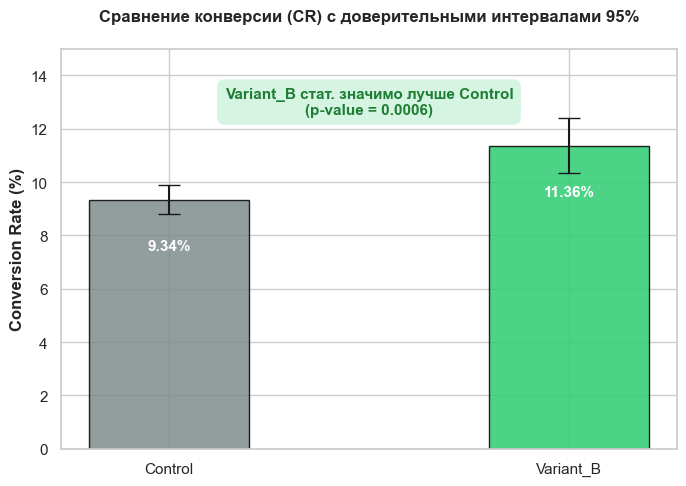

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))

# Данные для отрисовки (берем Control и Variant_B)
groups_plot = ['Control', 'Variant_B']
rates_plot = [final_summary.loc[0, 'conversion_rate'], final_summary.loc[2, 'conversion_rate']]
errors_y = [err_ctrl[0][0]*100, err_b[0][0]*100] # перевод в проценты

# Строим столбчатую диаграмму
bars = ax.bar(groups_plot, rates_plot, yerr=errors_y, capsize=8, 
              color=['#7f8c8d', '#2ecc71'], edgecolor='black', alpha=0.85, width=0.4)

# Добавляем цифровые значения на бары
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height - 2,
            f'{height:.2f}%', ha='center', va='bottom', color='white', weight='bold')

# Оформление
ax.set_title('Сравнение конверсии (CR) с доверительными интервалами 95%', pad=20, weight='bold')
ax.set_ylabel('Conversion Rate (%)', weight='bold')
ax.set_ylim(0, 15)

# Добавляем аналитическую плашку о стат-значимости
ax.text(0.5, 13, 'Variant_B стат. значимо лучше Control\n(p-value = 0.0006)', 
        bbox=dict(facecolor='#2ecc71', alpha=0.2, boxstyle='round,pad=0.5'),
        ha='center', va='center', color='#1e7e34', weight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Динамика накопительной конверсии по дням

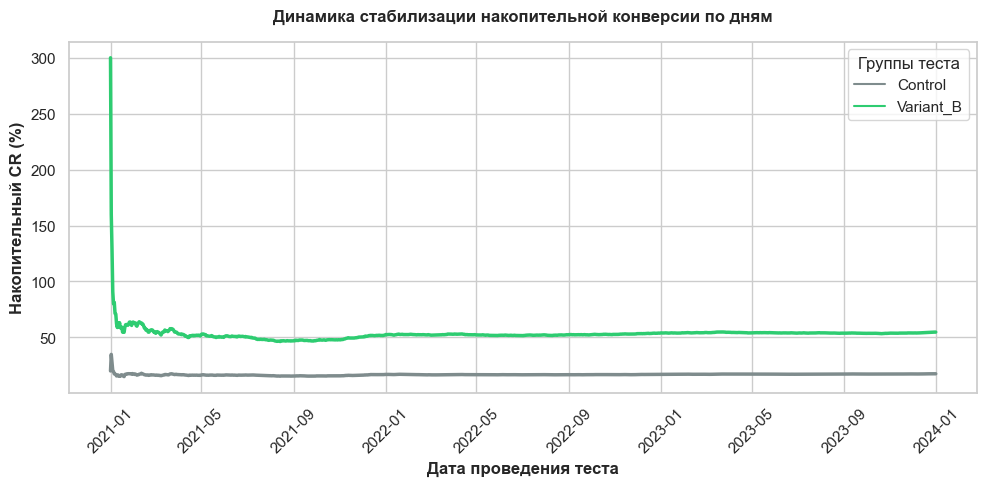

In [17]:
# 1. Извлекаем чистую дату (без часов и минут)
df_test_clean['date'] = df_test_clean['timestamp'].dt.date

# 2. Группируем пользователей по дням и группам
daily_data = df_test_clean.groupby(['date', 'experiment_group']).agg(
    daily_users=('customer_id', 'nunique')
).reset_index()

# Фильтруем только Control и Variant_B
daily_data = daily_data[daily_data['experiment_group'].isin(['Control', 'Variant_B'])]

# Считаем накопительную сумму пользователей по дням внутри каждой группы
daily_data['cum_users'] = daily_data.groupby('experiment_group')['daily_users'].cumsum()

# 3. Подтягиваем покупки по дням (делаем явную копию, чтобы убрать Warning)
campaign_purchases = campaign_purchases.copy()
campaign_purchases['date'] = campaign_purchases['timestamp'].dt.date

daily_purchases = campaign_purchases.groupby('date')['customer_id'].nunique().reset_index()
daily_purchases.columns = ['date', 'daily_purchases']

# Соединяем данные
daily_merged = pd.merge(daily_data, daily_purchases, on='date', how='left').fillna(0)
daily_merged['cum_purchases'] = daily_merged.groupby('experiment_group')['daily_purchases'].cumsum()

# Считаем накопительную конверсию в процентах
daily_merged['cum_cr'] = (daily_merged['cum_purchases'] / daily_merged['cum_users']) * 100

# 4. Строим график динамики
plt.figure(figsize=(10, 5))
sns.lineplot(data=daily_merged, x='date', y='cum_cr', hue='experiment_group', 
             palette=['#7f8c8d', '#2ecc71'], linewidth=2.5)

plt.title('Динамика стабилизации накопительной конверсии по дням', pad=15, weight='bold')
plt.xlabel('Дата проведения теста', weight='bold')
plt.ylabel('Накопительный CR (%)', weight='bold')
plt.xticks(rotation=45)
plt.legend(title='Группы теста')
plt.tight_layout()
plt.show()